# ML3 Validation

## 1. Введение 

### 1.1 Leave-one-out

Leave-one-out валидация - это метод кросс-валидации, при котором модель обучается на всех данных, кроме одного объекта, который используется для тетирования. Этот процесс повторяется для каждлго объекта в наборе данных.

| Плюсы (+) | Минусы (-) |
| :--- | :--- |
| **Максимум данных для обучения.** На каждом шаге модель учится на (N-1) объектах. Это почти весь датасет. | **Очень медленно.** Если у вас 1000 объектов, модель нужно обучить 1000 раз. |
| **Объективная оценка.** Нет случайности в разбиении (в отличие от k-fold). Результат детерминирован. | **Высокая дисперсия.** Так как тестовые выборки из одного объекта, метрика может сильно "скакать" в зависимости от выбросов. |
| **Идеально для малых данных.** Когда каждый пример на счету (например, всего 50 строк). | **Вычислительно дорого.** Требует много ресурсов и времени. |
| | **Нельзя стратифицировать.** В тесте всегда 1 объект, поэтому нельзя гарантировать баланс классов в тесте. |

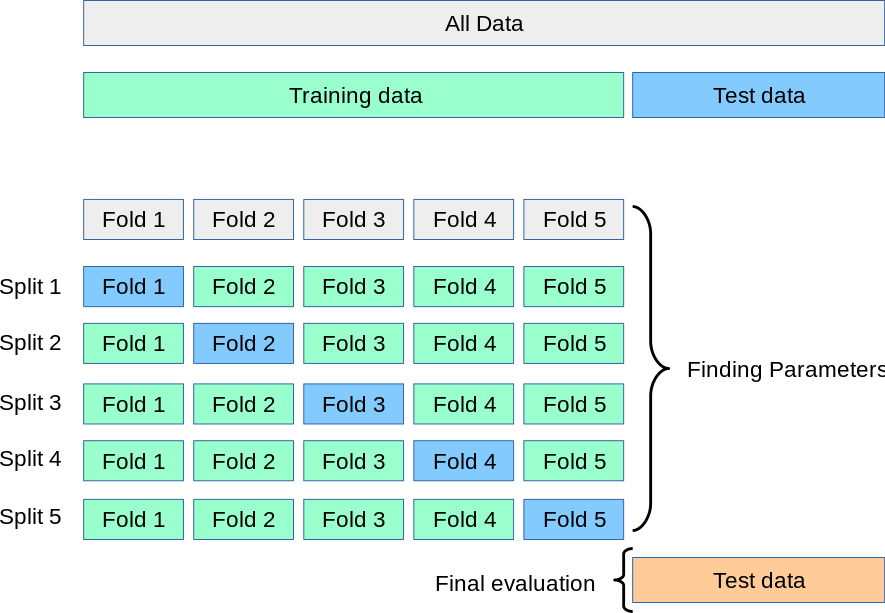

### 1.2 Grid Search, Randomized Grid Search, Bayesian optimization

**Grid Search**

Мы задаем список возможных значений каждого параметра. Алгоритм перебирает все возможные комбинации этих значений(декартово произведение). Для каждой комбинации модель обучается и оценивается(обычно через кросс-валидацию).

| Плюсы (+) | Минусы (-) |
| :--- | :--- |
| **Полнота.** Гарантированно найдет лучшую комбинацию *в пределах заданной сетки*. | **Очень медленно.** Количество комбинаций растет экспоненциально (проклятие размерности). |
| **Простота.** Легко понять и реализовать. | **Неэффективно.** Тратит время на заведомо плохие области параметров. |
| **Параллелизация.** Легко распараллелить вычисления. | **Дискретность.** Не проверяет значения между заданными точками (например, пропустит 4.5, если заданы 3 и 5). |

**Когда использовать:** когда параметров мало (1-3) и диапазоны значений небольшие.

**Randomized Grid Search**

Мы задаем распределения значений (или списки) для параметров, но вместо перебора всех комбинаций алгоритм выбирает случайное количество комбинаций(n_iter).

| Плюсы (+) | Минусы (-) |
| :--- | :--- |
| **Быстрее.** Вы сами контролируете бюджет времени через `n_iter`. | **Нет гарантий.** Может не найти глобальный оптимум (но часто находит хороший локальный). |
| **Эффективность.** Позволяет исследовать больше значений каждого параметра при том же бюджете. | **Случайность.** Результаты могут немного отличаться при разных запусках (нужен `random_state`). |
| **Непрерывность.** Удобно работать с непрерывными распределениями (например, `uniform`). | |

**Когда использовать:** стандартный выбор для большинства задач. Особенно когда параметров много или диапазоны значений широкие.

**Bayesian Optimization**

**Как работает:** это "умный поиск". Алгоритм строит вероятностную модель(суррогатную функцию) завичимостей качества модели от гиперпараметров на основе уже проверенных комбинаций. Он использует эту модель, чтобы предсказать какие следующие параметры с наибольшей вероятностью дадут улучшение(используя функцию приобретения / acquisition function).

| Плюсы (+) | Минусы (-) |
| :--- | :--- |
| **Самый эффективный.** Находит лучшие параметры за меньшее количество итераций. | **Сложнее в настройке.** Требует подключения сторонних библиотек (`Optuna`, `Hyperopt`). |
| **Учет истории.** Каждая следующая попытка умнее предыдущей. | **Последовательность.** Труднее распараллелить, так как каждый шаг зависит от предыдущих. |
| **Идеально для дорогих моделей.** Если одно обучение занимает часы, этот метод сэкономит дни. | |

**Когда использвать:** когда обучение модели занимает много времени, данных много, или очень важна точность

### 1.3 Classification of feature selection methods / Классификация методов отбора признаков

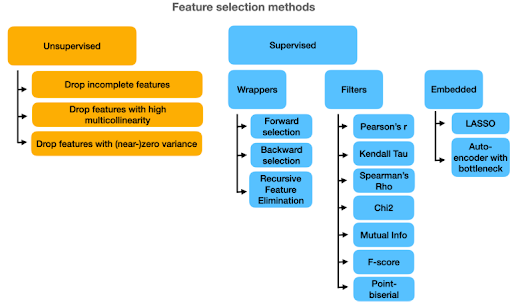

Все методы делятся на три основные группы в зависимости от того, как они взаимодействуют с моделью машинного обучения.

| Тип метода | Как работает | Плюсы (+) | Минусы (-) | Примеры |
| :--- | :--- | :--- | :--- | :--- |
| **Фильтрующие (Filter)** | Отбирают признаки до обучения модели, используя статистические критерии (корреляция, дисперсия). |  Очень быстро.<br>Не зависят от модели.<br>Хороши для первичного отсева. |  Игнорируют взаимодействие признаков.<br>Не учитывают специфику модели. | Pearson, Chi2, Variance Threshold |
| **Оберточные (Wrapper)** | Используют модель как «черный ящик». Обучают модель на разных подмножествах признаков и оценивают качество. |  Учитывают взаимодействие признаков.<br>Высокая точность отбора. |  Очень медленно (вычислительно дорого).<br>Риск переобучения. | Recursive Feature Elimination (RFE), Forward/Backward Selection |
| **Встроенные (Embedded)** | Отбор происходит в процессе обучения модели. Модель сама решает, какие признаки важны. |  Быстрее оберток.<br>Учитывают взаимодействие признаков.<br>Баланс скорости и качества. |  Привязаны к конкретному алгоритму модели. | Lasso (L1), Decision Trees (Feature Importance), ElasticNet |

**Статистические методы (фильтры)**

**Pearson Correlation (Корреляция Пирсона)**
**Для чего:** Оценка линейной зависимости между **непрерывными** признаками и целевой переменной (или между самими признаками для поиска мультиколлинеарности).

**Как работает:**
1.  Вычисляет ковариацию между двумя переменными.
2.  Нормализует её на произведение их стандартных отклонений.
3.  **Формула:**
    $$ r = \frac{\sum(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum(x_i - \bar{x})^2 \sum(y_i - \bar{y})^2}} $$
4.  **Результат:** Число от **-1 до 1**.
    *   `1`: Полная прямая связь (рост X → рост Y).
    *   `-1`: Полная обратная связь (рост X → падение Y).
    *   `0`: Линейной связи нет.

**Нюанс:** Не видит нелинейные зависимости (например, параболическую связь).

**Chi-Squared Test (Критерий хи-квадрат, $\chi^2$)**
**Для чего:** Оценка зависимости между **категориальными** признаками и категориальной целевой переменной (задачи классификации).

**Как работает:**
1.  Строит таблицу сопряженности (наблюдаемые частоты встречаемости классов для каждой категории признака).
2.  Вычисляет ожидаемые частоты, если бы признак и целевая переменная были независимы.
3.  Сравнивает наблюдаемые и ожидаемые значения.
4.  **Формула:**
    $$ \chi^2 = \sum \frac{(O_i - E_i)^2}{E_i} $$
    где $O_i$ — наблюдаемое значение, $E_i$ — ожидаемое.
5.  **Результат:** Чем выше значение $\chi^2$, тем меньше вероятность независимости (тем важнее признак). Обычно смотрят на p-value (если < 0.05, связь значима).

| Сравнение | Pearson | Chi-Squared |
| :--- | :--- | :--- |
| **Тип данных** | Непрерывные (Continuous) | Категориальные (Categorical) |
| **Тип связи** | Линейная | Любая зависимостью частот |
| **Задача** | Регрессия или Классификация | Только Классификация |
| **Диапазон** | [-1, 1] | [0, +∞) |

**Встроенные методы (Embedded)**

**Lasso (Least Absolute Shrinkage and Selection Operator)**
**Для чего:** Одновременно регуляризация (борьба с переобучением) и отбор признаков в линейных моделях.

**Как работает:**
1.  Это линейная регрессия (или логистическая), к функции потерь которой добавляется **L1-штраф**.
2.  **Функция потерь:**
    $$ Loss = MSE + \lambda \sum_{j=1}^{n} |w_j| $$
    где $w_j$ — веса признаков, $\lambda$ — сила регуляризации.
3.  **Эффект:** Из-за геометрии L1-штрафа (ромб вместо круга), оптимизация часто «загоняет» веса незначительных признаков ровно в **ноль**.
4.  **Результат:** Признаки с нулевым весом исключаются из модели.

**Плюсы:** Автоматически отбирает признаки, интерпретируемо.
**Минусы:** Если признаки сильно коррелируют, Lasso может случайно выбрать один из них и обнулить остальные.

**Важность признаков (Model-Based & Post-hoc)**

**Permutation Importance (Пермутационная важность)**
**Для чего:** Оценка важности признаков для **любой** обученной модели (model-agnostic).

**Как работает:**
1.  Обучают модель и замеряют базовую метрику качества (например, Accuracy) на тесте.
2.  Берут **один признак** и случайно перемешивают его значения в тестовой выборке (разрушают связь с целевой переменной).
3.  Снова замеряют метрику качества.
4.  **Важность** = `Базовая метрика` - `Метрика после перемешивания`.
5.  Если качество сильно упало → признак был важным. Если не изменилось → признак бесполезен.

**Плюсы:** Учитывает нелинейные связи, работает с любой моделью.
**Минусы:** Медленно (нужно много раз предсказывать), может быть смещена на коррелирующих признаках.

**SHAP (SHapley Additive exPlanations)**
**Для чего:** Глобальная и локальная интерпретация модели на основе теории игр.

**Как работает:**
1.  Основано на **значениях Шепли** из кооперативной теории игр.
2.  Рассматривает каждый признак как «игрока», а предсказание модели как «выигрыш».
3.  Вычисляет вклад каждого признака, перебирая все возможные комбинации признаков (коалиции) и оценивая, как меняется предсказание при добавлении конкретного признака.
4.  **Результат:**
    *   **Локально:** Для конкретного объекта показывает, почему модель выдала именно такое значение (например, «Возраст увеличил риск на 0.2, а Зарплата уменьшила на 0.1»).
    *   **Глобально:** Среднее абсолютное значение SHAP по всем объектам показывает общую важность признака.

**Плюсы:**
*   Теоретически обоснован (единственный метод с гарантиями консистентности).
*   Показывает **направление** влияния (плюс или минус).
*   Работает с любыми моделями (TreeSHAP для деревьев очень быстрый).

**Минусы:**
*   Вычислительно дорого для больших датасетов (если не использовать TreeSHAP).
*   Сложнее в интерпретации для новичков, чем просто «важность признаков».

| Сравнение | Permutation Importance | SHAP |
| :--- | :--- | :--- |
| **Основа** | Падение метрики качества | Теория игр (вклад в предсказание) |
| **Скорость** | Средняя (зависит от кол-ва признаков) | Медленная (кроме TreeSHAP) |
| **Направление** | Нет (только важность) | **Да** (плюс или минус влияние) |
| **Локальность** | Глобальная (для всей модели) | **Глобальная и Локальная** (для каждого объекта) |
| **Корреляция** | Может занижать важность коррелирующих признаков | Распределяет вклад между коррелирующими признаками |

## 2. Подготовка

Импортируем необходимые библиотеки:

In [1]:
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.preprocessing import MinMaxScaler
import random
from sklearn.model_selection import KFold, GroupKFold, StratifiedKFold, TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import shap
from sklearn.linear_model import ElasticNet
from scipy.stats import uniform
import optuna
from optuna.pruners import MedianPruner

Загрузим датасеты и подготовим данные:

In [2]:
input_df = pd.read_json('data/train.json')
input_df = input_df[['manager_id', 'created', 'features', 'price', 'bathrooms', 'bedrooms']]

Q1 = input_df['price'].quantile(0.25)
Q3 = input_df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

input_df = input_df[(input_df['price'] >= lower_bound) & (input_df['price'] <= upper_bound)]    

all_features = input_df['features'].to_list()
list_of_features = []
for pos in all_features:
    for ch in pos:
        list_of_features.append(ch)

counter = Counter(list_of_features)
features = list(dict(counter.most_common(20)).keys())

for name in features:
    input_df[name] = input_df['features'].apply(lambda x: 1 if name in x else 0)

input_df = input_df.drop(columns='features')
input_df.info()

<class 'pandas.DataFrame'>
Index: 46564 entries, 4 to 124009
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   manager_id           46564 non-null  str    
 1   created              46564 non-null  str    
 2   price                46564 non-null  int64  
 3   bathrooms            46564 non-null  float64
 4   bedrooms             46564 non-null  int64  
 5   Elevator             46564 non-null  int64  
 6   Cats Allowed         46564 non-null  int64  
 7   Hardwood Floors      46564 non-null  int64  
 8   Dogs Allowed         46564 non-null  int64  
 9   Doorman              46564 non-null  int64  
 10  Dishwasher           46564 non-null  int64  
 11  No Fee               46564 non-null  int64  
 12  Laundry in Building  46564 non-null  int64  
 13  Fitness Center       46564 non-null  int64  
 14  Pre-War              46564 non-null  int64  
 15  Laundry in Unit      46564 non-null  int64  
 16  R

## 3. Деление датасета на выборки

Создадим Python класс в который добавим методы деления данных на тренировочные, валидационные и тестовые по индексу, а так же по времени

In [3]:
class Split:
    def __init__(self, random_state=None):
        self.random_state=random_state
        if self.random_state is not None:
            random.seed(self.random_state)

    def train_test(self, df, test_size=0.2, shuffle=True):
        
        if not 0 < test_size < 1:
            raise ValueError("test_size должен быть от 0 до 1")
        
        df_work = df.copy()

        if shuffle:
            df_work = df_work.sample(frac=1, random_state=self.random_state).reset_index(drop=True)
        
        split_idx = int(len(df_work) * (1 - test_size))
        train_df = df_work.iloc[:split_idx]
        test_df = df_work.iloc[split_idx:]

        return train_df, test_df
    
    def train_val_test(self, df, test_size=0.2, validation_size=0.2,  shuffle=True):

        if validation_size + test_size >= 1:
            raise ValueError("Сумма test_size и validation_size должна быть меньше 1")
        
        df_work = df.copy()

        if shuffle:
            df_work = df_work.sample(frac=1, random_state=self.random_state).reset_index(drop=True)
        
        total_len = len(df_work)
        train_count = int(total_len * (1 - test_size - validation_size))
        val_count = int(total_len * validation_size)

        idx1 = train_count
        idx2 = train_count + val_count

        train_df = df_work.iloc[:idx1]
        val_df = df_work.iloc[idx1:idx2]
        test_df = df_work.iloc[idx2:]

        return train_df, val_df, test_df
    
    def time_split_train_test(self, df, date_col, date_split):

        df_work = df.copy()
        df_work[date_col] = pd.to_datetime(df_work[date_col])
        df_work = df_work.sort_values(date_col).reset_index(drop=True)
        train_df = df_work[df_work[date_col] <= date_split]
        test_df = df_work[df_work[date_col] > date_split]

        return train_df, test_df
    
    def time_split_train_val_test(self, df, date_col, validation_date, test_date):

        df_work = df.copy()
        df_work[date_col] = pd.to_datetime(df_work[date_col])
        df_work = df_work.sort_values(date_col).reset_index(drop=True)
        train_df = df_work[df_work[date_col] < validation_date]
        val_df = df_work[(df_work[date_col] < test_date) & (df_work[date_col] >= validation_date)]
        test_df = df_work[df_work[date_col] >= test_date]

        return train_df, val_df, test_df

Детерминированный процесс - это процесс, который при одинаковых входных данных и начальных условиях всегда приводит к одному и тому же результату.

Что бы сделать деление данных детерминированным, я добавил в конструктор класса переменную random_state, которая поумолчанию не имеет значения. Если передать значение в эту переменную при создании класса, то это значение будет является "зерном" при генерации псевдослучайного числа с помощью библиотеки random, и мы будем всегда получать один и тот же результат.

## 4. Cross-validation methods / Методы кросс-валидации данных

Создадим Python-класс для кросс=валидации данных и добавим в него различные методы:

In [4]:
class CrossVal:
    
    def __init__(self, random_state=None):
        self.random_state = random_state
        if self.random_state is not None:
            random.seed(self.random_state)
            np.random.seed(self.random_state)

    def _shuffle(self, indices):
        indices = indices.copy()
        np.random.shuffle(indices)

        return indices    
        
    def kFold(self, df, k=5, shuffle=True):

        n = len(df)
        indices = np.arange(n)
        if shuffle:
            indices = self._shuffle(indices)
        
        fold_size = n // k

        result = []

        for fold in range(k):
            test_start = fold * fold_size
            test_end = test_start + fold_size if fold < k - 1 else n
            test_idx = indices[test_start:test_end]
            train_idx = np.concatenate([indices[:test_start], indices[test_end:]])
            result.append((train_idx.tolist(), test_idx.tolist()))

        return result
           
    def grouped_kFold(self, df, k, group_field=None):

        if group_field is None:
            return self.kFold(df, k)
        
        groups = df[group_field].values
        indices = np.arange(len(df))
        unique_groups = np.unique(groups)
        np.random.shuffle(unique_groups)

        group_to_fold = {g: i % k for i, g in enumerate(unique_groups)}

        result = []

        for fold in range(k):
            test_mask = np.array([group_to_fold[g] == fold for g in groups])
            test_idx = indices[test_mask]
            train_idx = indices[~test_mask]
            if len(test_idx) > 0 and len(train_idx) > 0:
                result.append((train_idx.tolist(), test_idx.tolist()))

        return result

    def stratified_kFold(self, df,  k=5, stratified_field=None, shuffle=True):

        if stratified_field is None:
            return self.kFold(df, k, shuffle)
        
        y = df[stratified_field].values
        classes = np.unique(y)
        class_indicies = {c: np.where(y == c)[0] for c in classes}

        if shuffle:
            for c in class_indicies:
                class_indicies[c] = self._shuffle(class_indicies[c])

        fold_indices = [[] for _ in range(k)]
        for c, indices in class_indicies.items():
            fold_size = len(indices) // k
            for fold in range(k):
                start = fold * fold_size
                end = start + fold_size if fold < k - 1 else len(indices)
                fold_indices[fold].extend(indices[start:end])

        result = []
        for fold in range(k):
            test_idx = np.array(fold_indices[fold])
            train_idx = np.concatenate([np.array(fold_indices[i]) for i in range(k) if i != fold])
            result.append((train_idx.tolist(), test_idx.tolist()))

        return result

    def time_series_split(self, df, date_field, k=5):
        df_work = df.copy()
        
        if date_field is not None:
            df_work[date_field] = pd.to_datetime(df_work[date_field])
            df_work = df_work.sort_values(date_field).reset_index(drop=True)

            n = len(df_work)
            indices = np.arange(n)
            test_size = n // (k + 1)
            min_train = test_size * 2

            result = []
            for fold in range(k):
                train_size = min_train + fold * test_size
                if train_size + test_size > n:
                    break
                train_idx = indices[:train_size]
                test_idx = indices[train_size:train_size + test_size]
                result.append((train_idx.tolist(), test_idx.tolist()))
      
        return result


## 5. Сравнение собственных методов с методами sklearn

In [5]:
X = input_df.drop(columns=['price'])
y = input_df['price']
groups = X['manager_id']
split = CrossVal(random_state=21)

kfold_list = split.kFold(X)
group_kfold_list = split.grouped_kFold(X, group_field='manager_id', k=5)

price_min = input_df['price'].min()
price_max = input_df['price'].max()
split_price = (price_max - price_min) / 3
price_medium = price_min + split_price
input_df['price_class'] = pd.qcut(input_df['price'], q=3, labels=['0', '1', '2'], duplicates='drop')

stratified_kfold_list = split.stratified_kFold(input_df, 5, 'price_class')
time_split_list = split.time_series_split(X, 'created')

In [6]:
kfold_sklearn = KFold(n_splits=5, random_state=21, shuffle=True)
kfold_sklearn_list = list(kfold_sklearn.split(X))

group_kfold_sklearn = GroupKFold(n_splits=5)
group_kfold_sklearn_list = list(group_kfold_sklearn.split(X, y, groups))

stratified_kfold_sklearn = StratifiedKFold(n_splits=5, random_state=21, shuffle=True)
stratified_kfold_sklearn_list = list(stratified_kfold_sklearn.split(X, input_df['price_class']))

X_sorted = X.sort_values('created')
y_sorted = y.loc[X_sorted.index]

time_split_sklearn = TimeSeriesSplit(n_splits=5)
time_split_sklearn_list = list(time_split_sklearn.split(X_sorted))

Проверим, что наш GroupKFold работает корректно и не допускает одинаковых групп в выборках:

In [7]:
print("Проверка GroupKFold:\n")
all_folds_ok = True

for fold, (train_idx, test_idx) in enumerate(group_kfold_list, 1):
    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    overlap = train_groups & test_groups
    if overlap:
        print(f"fold {fold}: пересечение групп {overlap}")
        all_folds_ok = False
    else:
        print(f"Fold {fold}: Группы разделены корректно ✅ (train: {len(train_groups)})")

print(f"\n{'GroupKFold работает корректно - нет пересечений групп в тренировочных и тестовых выборках' if all_folds_ok else 'Обнаружены проблемы работы GroupKFold'}")

Проверка GroupKFold:

Fold 1: Группы разделены корректно ✅ (train: 2684)
Fold 2: Группы разделены корректно ✅ (train: 2684)
Fold 3: Группы разделены корректно ✅ (train: 2684)
Fold 4: Группы разделены корректно ✅ (train: 2684)
Fold 5: Группы разделены корректно ✅ (train: 2684)

GroupKFold работает корректно - нет пересечений групп в тренировочных и тестовых выборках


Проверим, что StratifiedKFold работает корректно и сохраняет пропорцию классов в каждой выборке:

In [8]:
original_dist = input_df['price_class'].value_counts(normalize=True).sort_index()
print("Проверка StratifiedKFold:\n")
print(f"Исходное распределение: {original_dist.to_dict()}")

tolerance = 0.05
all_folds_ok = True

for fold, (train_idx, test_idx) in enumerate(stratified_kfold_list, 1):
    y_train = input_df.iloc[train_idx]['price_class']
    y_test = input_df.iloc[test_idx]['price_class']

    train_dist = y_train.value_counts(normalize=True).sort_index()
    test_dist = y_test.value_counts(normalize=True).sort_index()

    train_ok = all(abs(train_dist.get(cls, 0) - original_dist.get(cls, 0)) < tolerance 
                   for cls in original_dist.index)
    test_ok = all(abs(test_dist.get(cls, 0) - original_dist.get(cls, 0)) < tolerance 
                  for cls in original_dist.index)

    status = "✅" if (train_ok and test_ok) else "❌"
    print(f"{status} Fold {fold}:")
    print(f"   Train: {train_dist.to_dict()}")
    print(f"   Test:  {test_dist.to_dict()}")
    
    if not (train_ok and test_ok):
        all_folds_ok = False

print(f"\n{'StratifiedKFold сохраняет пропорции' if all_folds_ok else '❌ Пропорции нарушены!'}")

Проверка StratifiedKFold:

Исходное распределение: {'0': 0.3420024052916416, '1': 0.32484322652693065, '2': 0.3331543681814277}
✅ Fold 1:
   Train: {'0': 0.3419950606678836, '1': 0.3248416192419199, '2': 0.3331633200901965}
   Test:  {'0': 0.34203178694158076, '1': 0.32484965635738833, '2': 0.3331185567010309}
✅ Fold 2:
   Train: {'0': 0.3419950606678836, '1': 0.3248416192419199, '2': 0.3331633200901965}
   Test:  {'0': 0.34203178694158076, '1': 0.32484965635738833, '2': 0.3331185567010309}
✅ Fold 3:
   Train: {'0': 0.3419950606678836, '1': 0.3248416192419199, '2': 0.3331633200901965}
   Test:  {'0': 0.34203178694158076, '1': 0.32484965635738833, '2': 0.3331185567010309}
✅ Fold 4:
   Train: {'0': 0.3419950606678836, '1': 0.3248416192419199, '2': 0.3331633200901965}
   Test:  {'0': 0.34203178694158076, '1': 0.32484965635738833, '2': 0.3331185567010309}
✅ Fold 5:
   Train: {'0': 0.34203178694158076, '1': 0.32484965635738833, '2': 0.3331185567010309}
   Test:  {'0': 0.3418849291541434, '1

Для нашего датасета лучше всего использовать **StrarifiedKFold** т.к. мы имеем выбросы в целевом столбце. Для этого нужно будет предобработать его поделить цены на отдельные категории, что бы сохранить пропорции при делении на выборки. Однако почистить целевой столбец от выбросов, то можно использовать обычный **KFold**. 

## 6. Отбор признаков

Нормализуем признаки и поделим данные на 3 части по времени:

In [9]:
split = Split(random_state=21)
train_df, val_df, test_df = split.train_val_test(input_df)
y_train = train_df['price']
y_val = val_df['price']
y_test = test_df['price']

cols_to_drop = ['price', 'price_class', 'manager_id', 'created']
X_train = train_df.drop(columns=cols_to_drop)
X_val = val_df.drop(columns=cols_to_drop)
X_test = test_df.drop(columns=cols_to_drop)

scaler = MinMaxScaler()
scaler.fit_transform(X_train)
scaler.transform(X_val)
scaler.transform(X_test)

array([[0.44444444, 0.5       , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.22222222, 0.33333333, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.22222222, 0.5       , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.22222222, 0.33333333, 1.        , ..., 0.        , 0.        ,
        0.        ],
       [0.22222222, 0.33333333, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.44444444, 0.33333333, 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(9314, 22))

Обучим модель Lasso Regression и получим топ-10 признаков по их коэффициентам:

In [10]:
lasso = Lasso(random_state=21)
lasso.fit(X_train, y_train)
y_train_pred = lasso.predict(X_train)
y_val_pred = lasso.predict(X_val)
y_test_pred = lasso.predict(X_test)
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': lasso.coef_
})
coef_df = coef_df.sort_values('coefficient', key=abs, ascending=False).reset_index(drop=True)
coef_df.head(10)

,feature,coefficient
0,bathrooms,850.197845
1,Doorman,545.750863
2,bedrooms,464.467859
3,Laundry in Unit,285.631229
4,Laundry In Building,-216.680548
5,Dishwasher,210.949808
6,Fitness Center,203.790014
7,High Speed Internet,-186.039278
8,Elevator,177.222651
9,Laundry in Building,-147.124435


### 6.1 Признаки с наибольшими весами

Переобучим модель на 10 лучших признаках и сравним точность:

In [11]:
top10 = coef_df['feature'].values
X_train_top = X_train[top10]
X_val_top = X_val[top10]
X_test_top = X_test[top10]

lasso_top = Lasso(random_state=21)
lasso_top.fit(X_train_top, y_train)

y_train_top_pred = lasso_top.predict(X_train_top)
y_val_top_pred = lasso_top.predict(X_val_top)
y_test_top_pred = lasso_top.predict(X_test_top)

In [12]:
mae = pd.DataFrame({
    'model': ['Lasso MinMaxScaler', 'Lasso top-10 MinMaxScaler'],
    'train': [mean_absolute_error(y_train, y_train_pred), mean_absolute_error(y_train, y_train_top_pred)],
    'valid': [mean_absolute_error(y_val, y_val_pred), mean_absolute_error(y_val, y_val_top_pred)],
    'test': [mean_absolute_error(y_test, y_test_pred), mean_absolute_error(y_test, y_test_top_pred)]
})

In [13]:
mae

,model,train,valid,test
0,Lasso MinMaxScaler,596.214549,598.192377,591.743398
1,Lasso top-10 MinMaxScaler,596.214164,598.190949,591.743328


In [14]:
rmse = pd.DataFrame({
    'model': ['Lasso MinMaxScaler', 'Lasso top-10 MinMaxScaler'],
    'train': [root_mean_squared_error(y_train, y_train_pred), root_mean_squared_error(y_train, y_train_top_pred)],
    'valid': [root_mean_squared_error(y_val, y_val_pred), root_mean_squared_error(y_val, y_val_top_pred)],
    'test': [root_mean_squared_error(y_test, y_test_pred), root_mean_squared_error(y_test, y_test_top_pred)]
})

In [15]:
rmse

,model,train,valid,test
0,Lasso MinMaxScaler,781.198830,790.374339,782.013119
1,Lasso top-10 MinMaxScaler,781.198585,790.372516,782.012901


In [16]:
r2 = pd.DataFrame({
    'model': ['Lasso MinMaxScaler', 'Lasso top-10 MinMaxScaler'],
    'train': [r2_score(y_train, y_train_pred), r2_score(y_train, y_train_top_pred)],
    'valid': [r2_score(y_val, y_val_pred), r2_score(y_val, y_val_top_pred)],
    'test': [r2_score(y_test, y_test_pred), r2_score(y_test, y_test_top_pred)]
})

In [17]:
r2

,model,train,valid,test
0,Lasso MinMaxScaler,0.524647,0.514620,0.512877
1,Lasso top-10 MinMaxScaler,0.524648,0.514623,0.512877


### 6.2 Неинформативные признаки(отсутствующие значения и низкая корреляция)

Создадим метод для отсеивания признаков с большим колл-ом пропущенных значений(NaN-ratio) и низкой корреляцией:

In [18]:
def drop_nan_features(X, y, nan_threshold=0.5, top_n=10):
    df_work = X.copy()

    nan_ratio = df_work.isna().sum() / len(df_work)
    valid_features = nan_ratio[nan_ratio <= nan_threshold].index.tolist()

    correlations = {}

    for feature in valid_features:
        corr = df_work[feature].corr(y)
        correlations[feature] = abs(corr)

    corr_df = pd.DataFrame({
        'feature': list(correlations.keys()),
        'correlation': list(correlations.values()),
        'nan_ratio': [nan_ratio[f] for f in correlations.keys()]
    })
        
    corr_df = corr_df.sort_values('correlation', ascending=False)
    top_features = corr_df.head(top_n)['feature'].tolist()

    return top_features

In [19]:
top_corr = drop_nan_features(X_train, y_train, top_n=10)
print(f"Лучшие признаки по корреляции:")
for i in top_corr:
    print(i)

Лучшие признаки по корреляции:
bedrooms
bathrooms
Doorman
Dishwasher
Fitness Center
Elevator
Laundry in Unit
Dining Room
No Fee
Laundry in Building


Обучим модель на этих признаках и сравним показатели:

In [20]:
X_train_corr = X_train[top_corr]
X_val_corr = X_val[top_corr]
X_test_corr = X_test[top_corr]

lasso_corr = Lasso(random_state=21)
lasso_corr.fit(X_train_corr, y_train)
y_train_corr_pred = lasso_corr.predict(X_train_corr)
y_val_corr_pred = lasso_corr.predict(X_val_corr)
y_test_corr_pred = lasso_corr.predict(X_test_corr)

mae = pd.concat([mae, pd.DataFrame({
    'model': ['Lasso best corr'],
    'train': [mean_absolute_error(y_train, y_train_corr_pred)],
    'valid': [mean_absolute_error(y_val, y_val_corr_pred)],
    'test': [mean_absolute_error(y_test, y_test_corr_pred)]
    })])

rmse = pd.concat([rmse, pd.DataFrame({
    'model': ['Lasso best corr'],
    'train': [root_mean_squared_error(y_train, y_train_corr_pred)],
    'valid': [root_mean_squared_error(y_val, y_val_corr_pred)],
    'test': [root_mean_squared_error(y_test, y_test_corr_pred)]
    })])

r2 = pd.concat([r2, pd.DataFrame({
    'model': ['Lasso best corr'],
    'train': [r2_score(y_train, y_train_corr_pred)],
    'valid': [r2_score(y_val, y_val_corr_pred)],
    'test': [r2_score(y_test, y_test_corr_pred)]
    })])


In [21]:
mae.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,596.214549,598.192377,591.743398
1,Lasso top-10 MinMaxScaler,596.214164,598.190949,591.743328
2,Lasso best corr,603.874452,606.919837,599.107601


In [22]:
rmse.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,781.198830,790.374339,782.013119
1,Lasso top-10 MinMaxScaler,781.198585,790.372516,782.012901
2,Lasso best corr,788.863423,798.749139,789.867759


In [23]:
r2.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,0.524647,0.514620,0.512877
1,Lasso top-10 MinMaxScaler,0.524648,0.514623,0.512877
2,Lasso best corr,0.515274,0.504280,0.503043


Как мы видим, модель обученная на признаках с наибольшей коррелцией показала результаты лучше

### 6.3 Permutation importance

In [24]:
lasso_permutation = Lasso(random_state=21)
lasso_permutation.fit(X_train, y_train)
perm = permutation_importance(
    lasso_permutation,
    X_val,
    y_val,
    n_repeats=5,
    random_state=21,
    scoring='neg_mean_absolute_percentage_error'
)

permutation_importance_top = pd.DataFrame({
    'feature': X_train.columns,
    'importance': perm.importances_mean
})

permutation_importance_top = permutation_importance_top.sort_values('importance', ascending=False)
permutation_importance_top = permutation_importance_top.head(10)
top_features_permut = permutation_importance_top['feature'].values
permutation_importance_top


,feature,importance
1,bedrooms,0.080024
0,bathrooms,0.031469
6,Doorman,0.029512
7,Dishwasher,0.005166
12,Laundry in Unit,0.004730
10,Fitness Center,0.004239
2,Elevator,0.003971
4,Hardwood Floors,0.001330
9,Laundry in Building,0.001229
18,Laundry In Building,0.001155


Переобучим модель по этим признакам:

In [25]:
X_train_perm = X_train[top_features_permut]
X_val_perm = X_val[top_features_permut]
X_test_perm = X_test[top_features_permut]

lasso_perm = Lasso(random_state=21)
lasso_perm.fit(X_train_perm, y_train)
y_train_perm_pred = lasso_perm.predict(X_train_perm)
y_val_perm_pred = lasso_perm.predict(X_val_perm)
y_test_perm_pred = lasso_perm.predict(X_test_perm)

mae = pd.concat([mae, pd.DataFrame({
    'model': ['Lasso permutation importance'],
    'train': [mean_absolute_error(y_train, y_train_perm_pred)],
    'valid': [mean_absolute_error(y_val, y_val_perm_pred)],
    'test': [mean_absolute_error(y_test, y_test_perm_pred)]
    })])

rmse = pd.concat([rmse, pd.DataFrame({
    'model': ['Lasso permutation importance'],
    'train': [root_mean_squared_error(y_train, y_train_perm_pred)],
    'valid': [root_mean_squared_error(y_val, y_val_perm_pred)],
    'test': [root_mean_squared_error(y_test, y_test_perm_pred)]
    })])

r2 = pd.concat([r2, pd.DataFrame({
    'model': ['Lasso permutation importance'],
    'train': [r2_score(y_train, y_train_perm_pred)],
    'valid': [r2_score(y_val, y_val_perm_pred)],
    'test': [r2_score(y_test, y_test_perm_pred)]
    })])


In [26]:
mae.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,596.214549,598.192377,591.743398
1,Lasso top-10 MinMaxScaler,596.214164,598.190949,591.743328
2,Lasso best corr,603.874452,606.919837,599.107601
3,Lasso permutation importance,601.236966,602.505361,597.105550


In [27]:
rmse.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,781.198830,790.374339,782.013119
1,Lasso top-10 MinMaxScaler,781.198585,790.372516,782.012901
2,Lasso best corr,788.863423,798.749139,789.867759
3,Lasso permutation importance,786.837390,794.755232,787.698387


In [28]:
r2.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,0.524647,0.514620,0.512877
1,Lasso top-10 MinMaxScaler,0.524648,0.514623,0.512877
2,Lasso best corr,0.515274,0.504280,0.503043
3,Lasso permutation importance,0.517761,0.509225,0.505769


Результаты практически не изменились

### 6.4 Shap

Получим топ-10 признаков с помощью Shap:

In [29]:
lasso_shap1 = Lasso(random_state=21)
lasso_shap1.fit(X_train, y_train)
explainer = shap.LinearExplainer(lasso_shap1, X_train, feature_names=X_train.columns)
shap_values = explainer.shap_values(X_train)
shap_importance = np.abs(shap_values).mean(axis=0)
feature_importance_shap = pd.DataFrame({
    'feature': X_train.columns,
    'shap_importance': shap_importance
})
feature_importance_shap = feature_importance_shap.sort_values('shap_importance', ascending=False).head(10)
features_shap = feature_importance_shap['feature'].values
feature_importance_shap

,feature,shap_importance
1,bedrooms,417.226400
6,Doorman,260.030811
0,bathrooms,198.805337
7,Dishwasher,101.890917
2,Elevator,88.673491
10,Fitness Center,76.231091
12,Laundry in Unit,73.547639
9,Laundry in Building,64.989420
4,Hardwood Floors,61.853494
5,Dogs Allowed,45.777921


Обучим модель по этим признакам и сравним результаты:

In [30]:
X_train_shap = X_train[features_shap]
X_val_shap = X_val[features_shap]
X_test_shap = X_test[features_shap]

lasso_shap = Lasso(random_state=21)
lasso_shap.fit(X_train_shap, y_train)
y_train_shap_pred = lasso_shap.predict(X_train_shap)
y_val_shap_pred = lasso_shap.predict(X_val_shap)
y_test_shap_pred = lasso_shap.predict(X_test_shap)

mae = pd.concat([mae, pd.DataFrame({
    'model': ['Lasso shap'],
    'train': [mean_absolute_error(y_train, y_train_shap_pred)],
    'valid': [mean_absolute_error(y_val, y_val_shap_pred)],
    'test': [mean_absolute_error(y_test, y_test_shap_pred)]
    })])

rmse = pd.concat([rmse, pd.DataFrame({
    'model': ['Lasso shap'],
    'train': [root_mean_squared_error(y_train, y_train_shap_pred)],
    'valid': [root_mean_squared_error(y_val, y_val_shap_pred)],
    'test': [root_mean_squared_error(y_test, y_test_shap_pred)]
    })])

r2 = pd.concat([r2, pd.DataFrame({
    'model': ['Lasso shap'],
    'train': [r2_score(y_train, y_train_shap_pred)],
    'valid': [r2_score(y_val, y_val_shap_pred)],
    'test': [r2_score(y_test, y_test_shap_pred)]
    })])

In [31]:
mae.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,596.214549,598.192377,591.743398
1,Lasso top-10 MinMaxScaler,596.214164,598.190949,591.743328
2,Lasso best corr,603.874452,606.919837,599.107601
3,Lasso permutation importance,601.236966,602.505361,597.105550
4,Lasso shap,601.923882,603.808173,597.989528


In [32]:
rmse.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,781.198830,790.374339,782.013119
1,Lasso top-10 MinMaxScaler,781.198585,790.372516,782.012901
2,Lasso best corr,788.863423,798.749139,789.867759
3,Lasso permutation importance,786.837390,794.755232,787.698387
4,Lasso shap,787.561395,796.447832,788.990158


In [33]:
r2.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,0.524647,0.514620,0.512877
1,Lasso top-10 MinMaxScaler,0.524648,0.514623,0.512877
2,Lasso best corr,0.515274,0.504280,0.503043
3,Lasso permutation importance,0.517761,0.509225,0.505769
4,Lasso shap,0.516873,0.507132,0.504146


## 7. Оптимизация гиперпараметров

Подберем оптимальные параметры для модели ElasticNet с помощью GridSearch и RandomSearch:

### 7.1 GridSearch

In [34]:
param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10],
    'l1_ratio':[0.1, 0.25, 0.5, 0.75, 1]
}

grid_search = GridSearchCV(
    estimator=ElasticNet(random_state=21),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)
print(f"Лучшие параметры: {grid_search.best_params_}")
elastic_gs = ElasticNet(**grid_search.best_params_)
elastic_gs.fit(X_train, y_train)
y_train_gs = elastic_gs.predict(X_train)
y_val_gs = elastic_gs.predict(X_val)
y_test_gs = elastic_gs.predict(X_test)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Лучшие параметры: {'alpha': 0.001, 'l1_ratio': 0.1}


### 7.3 RandomSearch

In [35]:
param_grid_rs = {
    'alpha': uniform(0.01, 10),
    'l1_ratio': uniform(0.0, 1.0)
}

random_search = RandomizedSearchCV(
    estimator=ElasticNet(random_state=21),
    param_distributions=param_grid_rs,
    n_iter=70,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1,
    random_state=21
)

random_search.fit(X_train, y_train)
print(f"Лучшие параметры: {random_search.best_params_}")
elastic_rs = ElasticNet(**random_search.best_params_)
elastic_rs.fit(X_train, y_train)
y_train_rs = elastic_rs.predict(X_train)
y_val_rs = elastic_rs.predict(X_val)
y_test_rs = elastic_rs.predict(X_test)

Fitting 5 folds for each of 70 candidates, totalling 350 fits
Лучшие параметры: {'alpha': np.float64(0.03100500892840307), 'l1_ratio': np.float64(0.6729292499766939)}


### 7.3 Optuna

Теперь сделаем тоже самое, но с использованием Optuna:

In [36]:
def objective(trial):
    alpha = trial.suggest_float('alpha', 0.01, 10.0, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)

    elastic_op = ElasticNet(random_state=21, alpha=alpha, l1_ratio=l1_ratio)
    elastic_op.fit(X_train, y_train)

    y_val_op = elastic_op.predict(X_val)
    y_train_op = elastic_op.predict(X_train)
    y_test_op = elastic_op.predict(X_test)
    
    mae = mean_absolute_error(y_val, y_val_op)
    rmse = root_mean_squared_error(y_val, y_val_op)
    r2 = r2_score(y_val, y_val_op)

    mae_tr = mean_absolute_error(y_train, y_train_op)
    rmse_tr = root_mean_squared_error(y_train, y_train_op)
    r2_tr = r2_score(y_train, y_train_op)

    mae_test = mean_absolute_error(y_test, y_test_op)
    rmse_test = root_mean_squared_error(y_test, y_test_op)
    r2_test = r2_score(y_test, y_test_op)

    trial.set_user_attr('MAE tr', mae_tr)
    trial.set_user_attr('RMSE tr', rmse_tr)
    trial.set_user_attr('R2 tr', r2_tr)
    trial.set_user_attr('MAE val', mae)
    trial.set_user_attr('RMSE val', rmse)
    trial.set_user_attr('R2 val', r2)
    trial.set_user_attr('MAE test', mae_test)
    trial.set_user_attr('RMSE test', rmse_test)
    trial.set_user_attr('R2 test', r2_test)

    return mae

study = optuna.create_study(study_name="elastic", directions=['minimize'])
study.optimize(objective, n_trials=100, show_progress_bar=True)
print(f"Лучшие результаты: {study.best_params}")


[I 2026-03-13 13:10:03,155] A new study created in memory with name: elastic


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-03-13 13:10:03,398] Trial 0 finished with value: 724.957803798619 and parameters: {'alpha': 1.0298557009713438, 'l1_ratio': 0.013595509320854737}. Best is trial 0 with value: 724.957803798619.
[I 2026-03-13 13:10:03,695] Trial 1 finished with value: 624.272742910584 and parameters: {'alpha': 0.19000699278180697, 'l1_ratio': 0.3667789651899982}. Best is trial 1 with value: 624.272742910584.
[I 2026-03-13 13:10:03,953] Trial 2 finished with value: 598.7355376901602 and parameters: {'alpha': 0.7150802528973721, 'l1_ratio': 0.9944149482931404}. Best is trial 2 with value: 598.7355376901602.
[I 2026-03-13 13:10:04,234] Trial 3 finished with value: 609.7731813720391 and parameters: {'alpha': 0.10035135853267149, 'l1_ratio': 0.4508890468998027}. Best is trial 2 with value: 598.7355376901602.
[I 2026-03-13 13:10:04,339] Trial 4 finished with value: 754.5455044132369 and parameters: {'alpha': 1.5901176371910182, 'l1_ratio': 0.034866386676385974}. Best is trial 2 with value: 598.73553769

In [37]:
vis = optuna.visualization
fig = vis.plot_optimization_history(study)
fig.show()

С помощью Optuna мы получили лучшие показатели и подобрали оптимальные гиперпараметры за наименьшее количество попыток и время

### 7.4 Результаты

Добавим результаты в таблицы и сравним результаты:

In [38]:
mae = pd.concat([mae, pd.DataFrame({
    'model': ['ElasticNet GS', 'ElasticNet RS', 'ElasticNet Optuna'],
    'train': [mean_absolute_error(y_train, y_train_gs), mean_absolute_error(y_train, y_train_rs), study.best_trial.user_attrs['MAE tr']],
    'valid': [mean_absolute_error(y_val, y_val_gs), mean_absolute_error(y_val, y_val_rs), study.best_trial.user_attrs['MAE val']],
    'test': [mean_absolute_error(y_test, y_test_gs), mean_absolute_error(y_test, y_test_rs), study.best_trial.user_attrs['MAE test']]
    })])

rmse = pd.concat([rmse, pd.DataFrame({
    'model': ['ElasticNet GS', 'ElasticNet RS', 'ElasticNet Optuna'],
    'train': [root_mean_squared_error(y_train, y_train_gs), root_mean_squared_error(y_train, y_train_rs), study.best_trial.user_attrs['RMSE tr']],
    'valid': [root_mean_squared_error(y_val, y_val_gs), root_mean_squared_error(y_val, y_val_rs), study.best_trial.user_attrs['RMSE val']],
    'test': [root_mean_squared_error(y_test, y_test_gs), root_mean_squared_error(y_test, y_test_rs), study.best_trial.user_attrs['RMSE test']]
    })])

r2 = pd.concat([r2, pd.DataFrame({
    'model': ['ElasticNet GS', 'ElasticNet RS', 'ElasticNet Optuna'],
    'train': [r2_score(y_train, y_train_gs), r2_score(y_train, y_train_rs), study.best_trial.user_attrs['R2 tr']],
    'valid': [r2_score(y_val, y_val_gs), r2_score(y_val, y_val_rs), study.best_trial.user_attrs['R2 val']],
    'test': [r2_score(y_test, y_test_gs), r2_score(y_test, y_test_rs), study.best_trial.user_attrs['R2 test']]
    })])


In [39]:
mae.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,596.214549,598.192377,591.743398
1,Lasso top-10 MinMaxScaler,596.214164,598.190949,591.743328
2,Lasso best corr,603.874452,606.919837,599.107601
3,Lasso permutation importance,601.236966,602.505361,597.105550
4,Lasso shap,601.923882,603.808173,597.989528
5,ElasticNet GS,596.001011,598.139839,591.753467
6,ElasticNet RS,597.320350,599.566441,592.308610
7,ElasticNet Optuna,595.915614,598.039605,591.744031


In [40]:
rmse.reset_index(drop=True)

,model,train,valid,test
0,Lasso MinMaxScaler,781.198830,790.374339,782.013119
1,Lasso top-10 MinMaxScaler,781.198585,790.372516,782.012901
2,Lasso best corr,788.863423,798.749139,789.867759
3,Lasso permutation importance,786.837390,794.755232,787.698387
4,Lasso shap,787.561395,796.447832,788.990158
5,ElasticNet GS,780.966874,790.485351,781.974024
6,ElasticNet RS,781.659366,791.004121,781.309752
7,ElasticNet Optuna,780.959954,790.497894,782.108046


In [41]:
r2.reset_index(drop=False)

,index,model,train,valid,test
0,0,Lasso MinMaxScaler,0.524647,0.514620,0.512877
1,1,Lasso top-10 MinMaxScaler,0.524648,0.514623,0.512877
2,0,Lasso best corr,0.515274,0.504280,0.503043
3,0,Lasso permutation importance,0.517761,0.509225,0.505769
4,0,Lasso shap,0.516873,0.507132,0.504146
5,0,ElasticNet GS,0.524930,0.514484,0.512926
6,1,ElasticNet RS,0.524087,0.513847,0.513753
7,2,ElasticNet Optuna,0.524938,0.514469,0.512759
